# 13.1  -  Landfall Rainfall: IMERG Observations & CHIRPS-GEFS Forecasts

For each historical WP tropical cyclone (1998-2024) that made landfall in a target region, the notebook:
1. Detects landfall time from IBTrACS best-track data — defined as the **midpoint** between
   the last offshore 6-hourly track point (p0) and the first inland point (p1), with wind speed
   interpolated as the mean of the two — giving the best estimate of the actual crossing moment
2. Queries IMERG for a **3-day window** around landfall (1 day before → 1 day after)
3. Computes 3-day accumulated rainfall per target region (observational)
4. Matches CHIRPS-GEFS forecasts to the same 3-day window at each lead time (0–5 days before landfall)
5. Checks whether CHIRPS-GEFS identifies the same wettest storms as IMERG

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import ocha_stratus as stratus
from shapely.geometry import LineString
from shapely.ops import unary_union

from src.datasources.imerg import fetch_imerg_data
from src.constants import CHD_GREEN, KNOTS_TO_KMH

In [2]:
# ── Constants ─────────────────────────────────────────────────────────────────
TARGET_REGIONS  = ["PH02", "PH03", "PH05", "PH08"]
DAYS_BEFORE     = 1    # day before landfall
DAYS_AFTER      = 1    # day after landfall  →  window = day -1, day 0, day +1
START_YEAR      = 1998  # IMERG starts 1998-01-01
END_YEAR        = 2024
N_YEARS         = END_YEAR - START_YEAR + 1

# Minimum IBTrACS wind speed (kt) for a storm to be included in the analysis.
# 34 kt = tropical storm  -  excludes tropical depressions.
MIN_WIND_KT     = 34.0

print(f"IMERG window : day before landfall  +  landfall day  +  day after  ({DAYS_BEFORE + 1 + DAYS_AFTER} days total)")
print(f"Record       : {START_YEAR}-{END_YEAR}  ({N_YEARS} years)")
print(f"Target regions: {TARGET_REGIONS}")

IMERG window : day before landfall  +  landfall day  +  day after  (3 days total)
Record       : 1998-2024  (27 years)
Target regions: ['PH02', 'PH03', 'PH05', 'PH08']


In [3]:
# ── Admin boundaries ─────────────────────────────────────────────────────────
phl_admin_1     = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=1)
pcode_col       = [c for c in phl_admin_1.columns if "src" in c.lower()][0]
target_rgn_gdf  = phl_admin_1[phl_admin_1[pcode_col].isin(TARGET_REGIONS)].copy()
target_union    = unary_union(target_rgn_gdf.geometry)

# Build a pcode → region name lookup for labelling
pcode_to_name = dict(zip(target_rgn_gdf[pcode_col], target_rgn_gdf["adm1_name"]))
print(f"Target regions: {pcode_to_name}")

Target regions: {'PH02': 'Region II (Cagayan Valley)', 'PH03': 'Region III (Central Luzon)', 'PH05': 'Region V (Bicol Region)', 'PH08': 'Region VIII (Eastern Visayas)'}


In [4]:
# ── IBTrACS tracks ────────────────────────────────────────────────────────────
def fetch_ibtracs(start_date, end_date):
    query = f"""
    SELECT storm_id, valid_time, wind_speed, geometry
    FROM storms.ibtracs_tracks_geo
    WHERE basin = 'WP'
      AND valid_time BETWEEN '{start_date}' AND '{end_date}'
    """
    return gpd.read_postgis(
        query, stratus.get_engine(stage="prod"), geom_col="geometry"
    )

tracks = fetch_ibtracs(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
tracks["valid_time"] = pd.to_datetime(tracks["valid_time"])
tracks["name"] = tracks["storm_id"].str.split("_").str[0].str.capitalize()
tracks["year"] = tracks["storm_id"].str.extract(r"_wp_(\d{4})$").astype(float)

print(f"Track points : {len(tracks):,}")
print(f"Unique storms: {tracks['storm_id'].nunique()}")

Track points : 27,274
Unique storms: 640


In [5]:
# ── Detect landfall in target regions ────────────────────────────────────────
# A landfall is recorded when a track segment (consecutive 6-h points) crosses
# from outside into the target-region boundary. The landfall time is linearly
# interpolated as the midpoint between p0 (last point outside) and p1 (first
# point inside), and wind speed is averaged between the two — giving the best
# estimate of conditions at the actual crossing moment.
#
# We require the storm to have at least MIN_WIND_KT at some point in its life
# (within the IMERG period) to exclude tropical depressions.

landfalls = []

for storm_id, grp in tracks.sort_values("valid_time").groupby("storm_id"):
    grp = grp.reset_index(drop=True)

    # Require at least tropical storm strength
    if grp["wind_speed"].max() < MIN_WIND_KT:
        continue

    # Walk consecutive track segments looking for first target-region crossing
    for i in range(len(grp) - 1):
        p0, p1 = grp.iloc[i], grp.iloc[i + 1]
        seg = LineString([
            (p0.geometry.x, p0.geometry.y),
            (p1.geometry.x, p1.geometry.y),
        ])
        if seg.intersects(target_union):
            mid_dt   = p0["valid_time"] + (p1["valid_time"] - p0["valid_time"]) / 2
            mid_wind = (p0["wind_speed"] + p1["wind_speed"]) / 2
            landfalls.append({
                "storm_id":            storm_id,
                "name":                grp["name"].iloc[0],
                "year":                grp["year"].iloc[0],
                "landfall_dt":         mid_dt,
                "landfall_date":       mid_dt.date(),
                "wind_at_landfall_kt": round(mid_wind, 1),
            })
            break

landfall_df = pd.DataFrame(landfalls)
print(f"Storms with landfall in target regions: {len(landfall_df)}")
print(f"Seasons: {landfall_df['year'].nunique():.0f}")

Storms with landfall in target regions: 142
Seasons: 26


In [6]:
# ── Fetch IMERG for each storm's 3-day window ─────────────────────────────────
# fetch_imerg_data returns daily stats per pcode; we use 'mean' (mm/day) and
# filter to adm_level=1 (region-level) for the four target pcodes.

all_imerg = []

for _, row in landfall_df.iterrows():
    lf_date   = pd.Timestamp(row["landfall_date"])
    win_start = lf_date - pd.Timedelta(days=DAYS_BEFORE)
    win_end   = lf_date + pd.Timedelta(days=DAYS_AFTER)

    df = fetch_imerg_data(
        pcodes=TARGET_REGIONS,
        start_date=win_start,
        end_date=win_end,
    )
    df = df[df["adm_level"] == 1].copy()
    df["storm_id"]     = row["storm_id"]
    df["landfall_date"] = row["landfall_date"]
    all_imerg.append(df)

imerg_df = pd.concat(all_imerg, ignore_index=True)
print(f"IMERG rows fetched: {len(imerg_df):,}")
print(f"Columns: {list(imerg_df.columns)}")

IMERG rows fetched: 1,688
Columns: ['iso3', 'pcode', 'valid_date', 'adm_level', 'mean', 'median', 'min', 'max', 'count', 'sum', 'std', 'storm_id', 'landfall_date']


In [7]:
# ── 3-day accumulated rainfall per storm × region ─────────────────────────────
# Sum the daily mean values over the window → 3-day total (mm) for each region.
rain_3day = (
    imerg_df.groupby(["storm_id", "pcode"])["mean"]
    .sum()
    .reset_index()
    .rename(columns={"mean": "rain_3day_mm"})
)
rain_3day["region"] = rain_3day["pcode"].map(pcode_to_name)

# Max rainfall across all target regions per storm
rain_max = (
    rain_3day.groupby("storm_id")["rain_3day_mm"]
    .max()
    .reset_index()
    .rename(columns={"rain_3day_mm": "max_rain_mm"})
)

# Merge with landfall metadata
exposure = (
    landfall_df[["storm_id", "name", "year", "landfall_date", "wind_at_landfall_kt"]]
    .merge(rain_max, on="storm_id")
    .sort_values("max_rain_mm", ascending=False)
    .reset_index(drop=True)
)
exposure.index += 1
exposure["max_wind_kmh"] = (exposure["wind_at_landfall_kt"] * KNOTS_TO_KMH).round(1)

print(f"Storms with IMERG data: {len(exposure)}")
display(exposure[["name", "year", "landfall_date", "max_wind_kmh", "max_rain_mm"]].head(15))

Storms with IMERG data: 142


,name,year,landfall_date,max_wind_kmh,max_rain_mm
1,Kujira,2009.0,2009-05-01,NaN,418.037654
2,Zeb,1998.0,1998-10-14,194.5,415.659430
3,Aere,2011.0,2011-05-07,64.8,400.458058
4,Babs,1998.0,1998-10-21,157.4,388.408500
5,Nock-ten,2011.0,2011-07-25,NaN,380.948882
6,Sanvu,2005.0,2005-08-11,74.1,365.377461
7,Ketsana,2009.0,2009-09-26,69.4,357.496551
8,Imbudo,2003.0,2003-07-22,143.5,343.308570
9,Rumbia,2000.0,2000-11-29,NaN,341.480642
10,Cimaron,2006.0,2006-10-29,175.9,338.373040


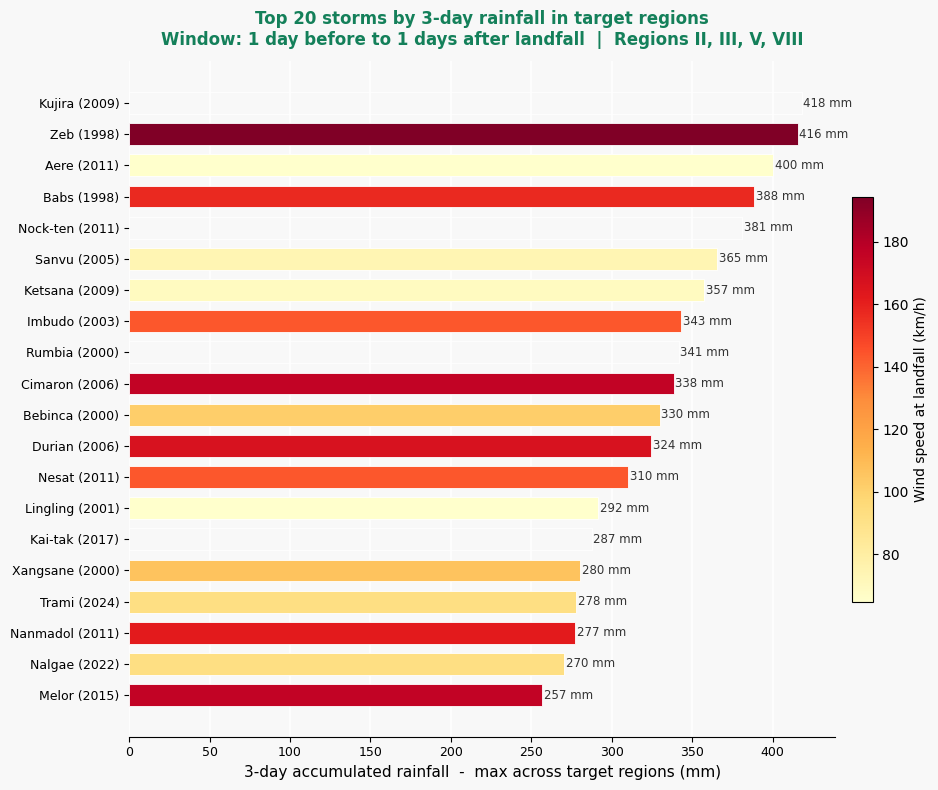

In [8]:
# ── Top 20 storms by 3-day rainfall in target regions ─────────────────────────
TOP_N   = 20
plot_df = exposure.head(TOP_N).copy()
plot_df["bar_label"] = plot_df["name"] + " (" + plot_df["year"].astype(int).astype(str) + ")"

norm_w = mcolors.Normalize(
    vmin=plot_df["max_wind_kmh"].min(),
    vmax=plot_df["max_wind_kmh"].max(),
)
colors = [cm.YlOrRd(norm_w(v)) for v in plot_df["max_wind_kmh"]]

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

bars = ax.barh(
    plot_df["bar_label"][::-1], plot_df["max_rain_mm"][::-1],
    color=colors[::-1], edgecolor="white", linewidth=0.6, height=0.7,
)
for bar, val in zip(bars, plot_df["max_rain_mm"][::-1]):
    ax.text(
        bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
        f"{val:.0f} mm",
        va="center", ha="left", fontsize=8.5, color="#333",
    )

sm = cm.ScalarMappable(cmap=cm.YlOrRd, norm=norm_w)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, aspect=20,
             label="Wind speed at landfall (km/h)")

ax.set_xlabel(f"{DAYS_BEFORE + 1 + DAYS_AFTER}-day accumulated rainfall  -  max across target regions (mm)",
              fontsize=11)
ax.set_title(
    f"Top {TOP_N} storms by 3-day rainfall in target regions\n"
    f"Window: {DAYS_BEFORE} day before to {DAYS_AFTER} days after landfall  |  Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", pad=12, color=CHD_GREEN,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.grid(True, color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()

In [9]:
# ── Per-region 3-day rainfall  -  pivot table ───────────────────────────────────
region_pivot = rain_3day.pivot_table(
    index="storm_id",
    columns="region",
    values="rain_3day_mm",
    aggfunc="sum",
    fill_value=0,
).reset_index()

region_pivot = region_pivot.merge(
    exposure[["storm_id", "name", "year", "max_rain_mm"]],
    on="storm_id",
).sort_values("max_rain_mm", ascending=False)

print("Top 20 storms  -  3-day rainfall (mm) per target region:")
display(region_pivot.drop(columns="storm_id").head(20).reset_index(drop=True))

Top 20 storms  -  3-day rainfall (mm) per target region:


,Region II (Cagayan Valley),Region III (Central Luzon),Region V (Bicol Region),Region VIII (Eastern Visayas),name,year,max_rain_mm
0,1.330329,6.536065,418.037654,62.523822,Kujira,2009.0,418.037654
1,415.659430,189.208594,85.341469,18.918003,Zeb,1998.0,415.659430
2,23.589413,29.006755,400.387750,400.458058,Aere,2011.0,400.458058
3,80.732023,138.324669,388.408500,273.252923,Babs,1998.0,388.408500
4,48.561443,74.360341,380.948882,176.109411,Nock-ten,2011.0,380.948882
5,365.377461,237.211683,58.623726,25.847485,Sanvu,2005.0,365.377461
6,150.972692,357.496551,189.945604,14.308314,Ketsana,2009.0,357.496551
7,248.927955,343.308570,90.755060,58.646165,Imbudo,2003.0,343.308570
8,21.945117,33.797562,341.480642,326.094020,Rumbia,2000.0,341.480642
9,338.373040,183.008145,38.622319,4.305793,Cimaron,2006.0,338.373040


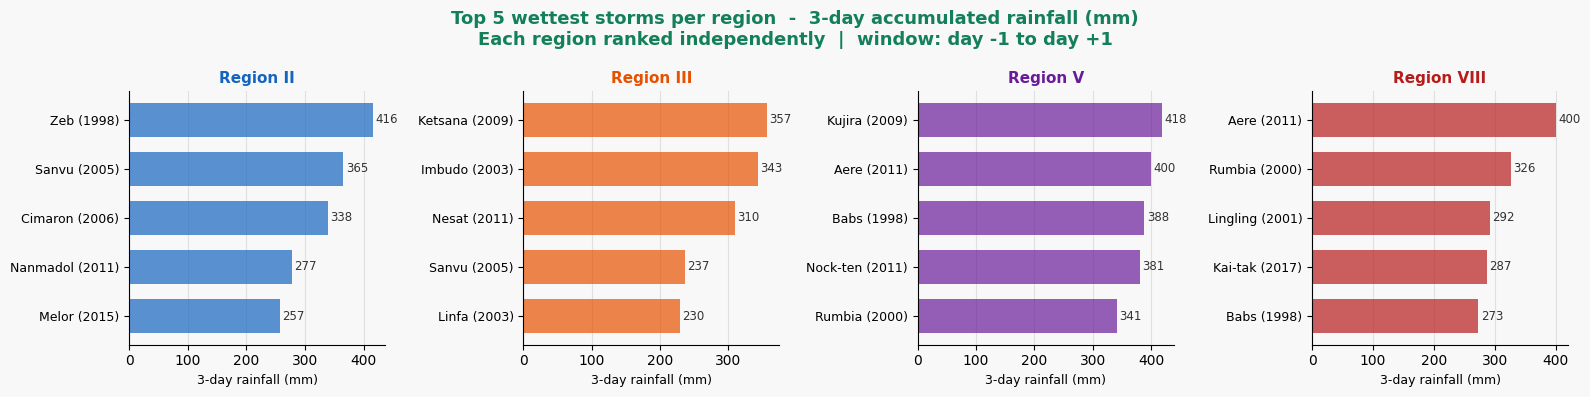

In [10]:
# ── Per-region ranking: wettest storms ────────────────────────────────────────
TOP_N = 5

rain_ranked = rain_3day.merge(
    exposure[["storm_id", "name", "year"]], on="storm_id", how="left"
)
rain_ranked["label"] = (
    rain_ranked["name"] + " (" + rain_ranked["year"].astype(int).astype(str) + ")"
)

FULL_NAMES = [
    "Region II (Cagayan Valley)",
    "Region III (Central Luzon)",
    "Region V (Bicol Region)",
    "Region VIII (Eastern Visayas)",
]
SHORT_NAMES = ["Region II", "Region III", "Region V", "Region VIII"]
REGION_COLORS = ["#1565C0", "#E65100", "#6A1B9A", "#B71C1C"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
fig.patch.set_facecolor("#f8f8f8")
fig.suptitle(
    f"Top {TOP_N} wettest storms per region  -  3-day accumulated rainfall (mm)\n"
    f"Each region ranked independently  |  window: day -{DAYS_BEFORE} to day +{DAYS_AFTER}",
    fontsize=13, fontweight="bold", color=CHD_GREEN,
)

for ax, full, short, color in zip(axes, FULL_NAMES, SHORT_NAMES, REGION_COLORS):
    ax.set_facecolor("#f8f8f8")
    top = (
        rain_ranked[rain_ranked["region"] == full]
        .nlargest(TOP_N, "rain_3day_mm")
        .sort_values("rain_3day_mm", ascending=True)
        .reset_index(drop=True)
    )
    ax.barh(range(len(top)), top["rain_3day_mm"], color=color, alpha=0.7, height=0.7)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top["label"], fontsize=9)
    for i, val in enumerate(top["rain_3day_mm"]):
        ax.text(val + top["rain_3day_mm"].max() * 0.01, i,
                f"{val:.0f}", va="center", fontsize=8.5, color="#333")
    ax.set_xlabel("3-day rainfall (mm)", fontsize=9)
    ax.set_title(short, fontsize=11, fontweight="bold", color=color)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.grid(True, color="#e0e0e0")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

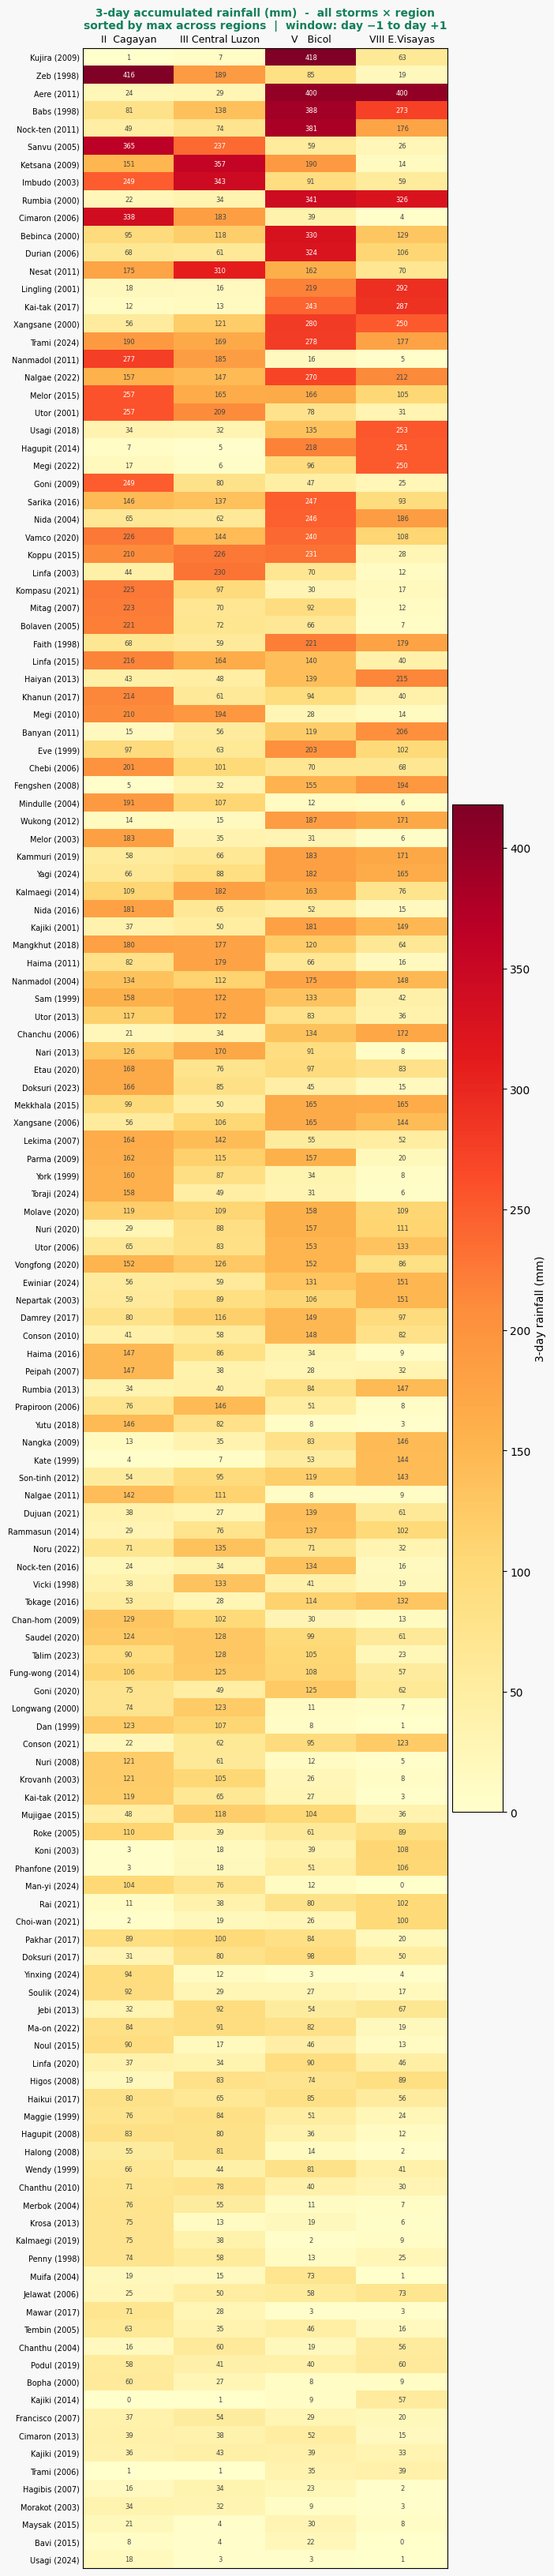

In [11]:
# ── Heatmap: 3-day rainfall per storm × region ────────────────────────────────
short_names = {
    "Region II (Cagayan Valley)":    "II  Cagayan",
    "Region III (Central Luzon)":    "III Central Luzon",
    "Region V (Bicol Region)":       "V   Bicol",
    "Region VIII (Eastern Visayas)": "VIII E.Visayas",
}
region_cols = list(short_names.keys())

plot_src = (
    region_pivot
    .sort_values("max_rain_mm", ascending=False)
    .reset_index(drop=True)
)
plot_src["label"] = (
    plot_src["name"] + " (" + plot_src["year"].astype(int).astype(str) + ")"
)

mat      = plot_src[region_cols].values
labels_y = plot_src["label"].tolist()
labels_x = [short_names[c] for c in region_cols]

n = len(labels_y)
fig, ax = plt.subplots(figsize=(7, n * 0.22 + 1.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0, vmax=mat.max())

ax.set_xticks(range(4))
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_yticks(range(n))
ax.set_yticklabels(labels_y, fontsize=7)
ax.tick_params(axis="x", labeltop=True, labelbottom=False, length=0)
ax.tick_params(axis="y", length=0)

# Cell annotations  -  white text on dark cells, dark on light
cutoff = mat.max() * 0.55
for r in range(n):
    for c in range(4):
        val = mat[r, c]
        color = "white" if val > cutoff else "#444"
        ax.text(c, r, f"{val:.0f}", ha="center", va="center",
                fontsize=6, color=color)

fig.colorbar(im, ax=ax, shrink=0.4, pad=0.01, label="3-day rainfall (mm)")
ax.set_title(
    "3-day accumulated rainfall (mm)  -  all storms × region\n"
    f"sorted by max across regions  |  window: day −{DAYS_BEFORE} to day +{DAYS_AFTER}",
    fontsize=10, fontweight="bold", color=CHD_GREEN, pad=18,
)
plt.tight_layout()
plt.show()

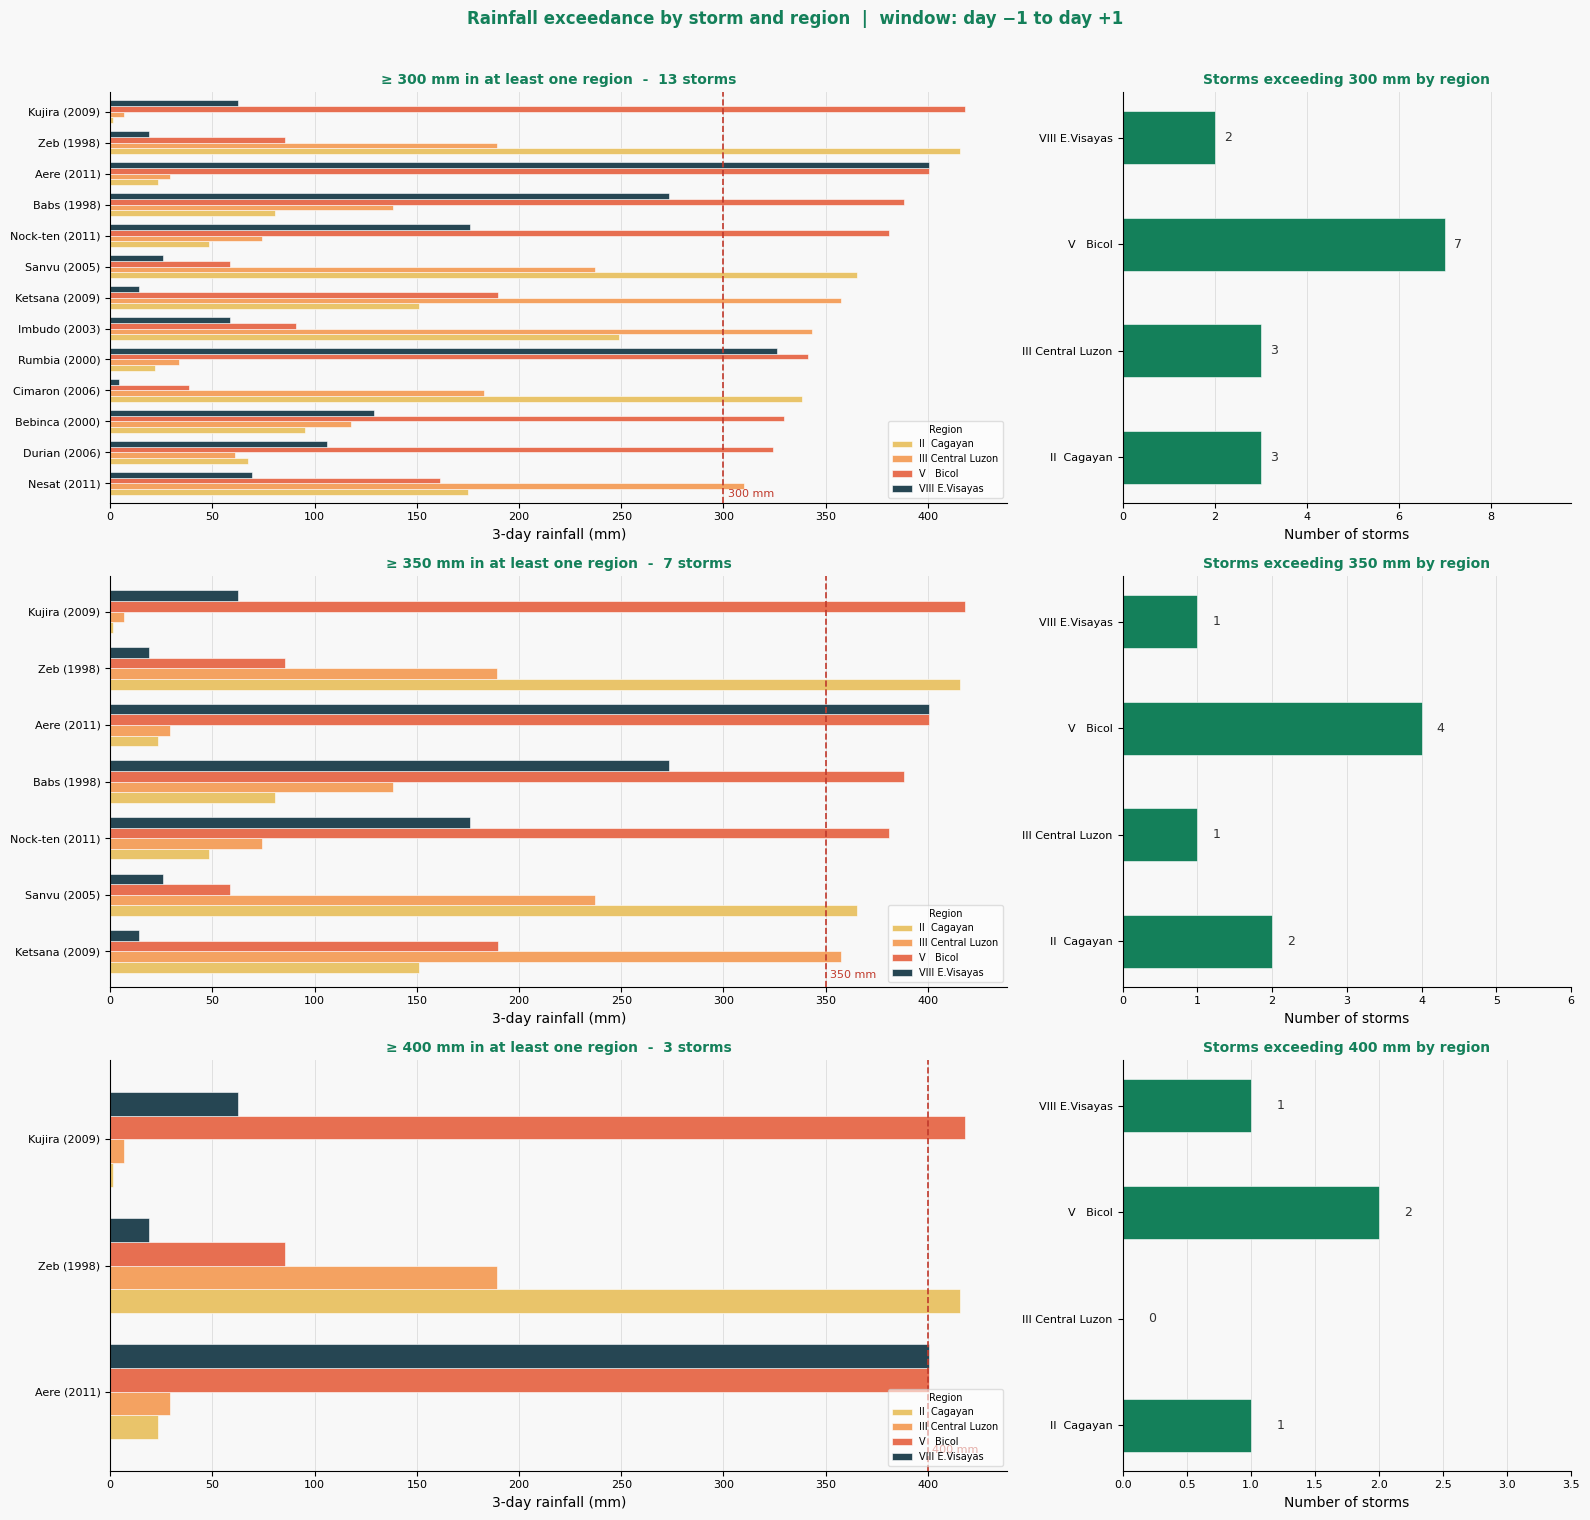

In [12]:
# ── Storms and regions exceeding rainfall thresholds ──────────────────────────
EXCEEDANCE_THRESHOLDS = [300, 350, 400]

# Long-form data with storm labels
rain_labeled = rain_3day.merge(
    exposure[["storm_id", "name", "year"]], on="storm_id"
)
rain_labeled["label"] = (
    rain_labeled["name"] + " (" + rain_labeled["year"].astype(int).astype(str) + ")"
)
rain_labeled["short_region"] = rain_labeled["region"].map(short_names)

fig, axes = plt.subplots(
    len(EXCEEDANCE_THRESHOLDS), 2,
    figsize=(16, len(EXCEEDANCE_THRESHOLDS) * 5),
    gridspec_kw={"width_ratios": [2, 1]},
)
fig.patch.set_facecolor("#f8f8f8")

for row, thr in enumerate(EXCEEDANCE_THRESHOLDS):
    # ── Left panel: storms where ANY region exceeds threshold ─────────────────
    ax_s = axes[row, 0]
    ax_s.set_facecolor("#f8f8f8")

    # storms where at least one region exceeded
    exceeded_storms = (
        rain_labeled[rain_labeled["rain_3day_mm"] >= thr]
        ["storm_id"].unique()
    )
    sub = (
        rain_labeled[rain_labeled["storm_id"].isin(exceeded_storms)]
        .pivot_table(index="label", columns="short_region",
                     values="rain_3day_mm", aggfunc="sum", fill_value=0)
    )
    # sort by max across regions
    sub = sub.loc[sub.max(axis=1).sort_values(ascending=True).index]

    colors_bar = ["#e9c46a", "#f4a261", "#e76f51", "#264653"]
    sub.plot(kind="barh", ax=ax_s, color=colors_bar[:len(sub.columns)],
             width=0.75, edgecolor="white", linewidth=0.4)

    # threshold line
    ax_s.axvline(thr, color="#c0392b", linewidth=1.2, linestyle="--", zorder=5)
    ax_s.text(thr + 2, -0.5, f"{thr} mm", color="#c0392b", fontsize=8, va="bottom")

    ax_s.set_xlabel("3-day rainfall (mm)", fontsize=10)
    ax_s.set_ylabel("")
    ax_s.set_title(
        f"≥ {thr} mm in at least one region  -  {len(exceeded_storms)} storms",
        fontsize=10, fontweight="bold", color=CHD_GREEN,
    )
    ax_s.spines[["top", "right"]].set_visible(False)
    ax_s.tick_params(labelsize=8)
    ax_s.legend(title="Region", fontsize=7, title_fontsize=7,
                loc="lower right", framealpha=0.6)
    ax_s.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_s.set_axisbelow(True)

    # ── Right panel: how many storms exceeded per region ──────────────────────
    ax_r = axes[row, 1]
    ax_r.set_facecolor("#f8f8f8")

    region_counts = (
        rain_labeled[rain_labeled["rain_3day_mm"] >= thr]
        .groupby("short_region")["storm_id"].nunique()
        .reindex([short_names[c] for c in region_cols], fill_value=0)
    )

    bars = ax_r.barh(
        region_counts.index, region_counts.values,
        color=CHD_GREEN, edgecolor="white", linewidth=0.4, height=0.5,
    )
    for bar, val in zip(bars, region_counts.values):
        ax_r.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
                  str(val), va="center", ha="left", fontsize=9, color="#333")

    ax_r.set_xlabel("Number of storms", fontsize=10)
    ax_r.set_title(
        f"Storms exceeding {thr} mm by region",
        fontsize=10, fontweight="bold", color=CHD_GREEN,
    )
    ax_r.set_xlim(0, region_counts.max() * 1.25 + 1)
    ax_r.spines[["top", "right"]].set_visible(False)
    ax_r.tick_params(labelsize=8)
    ax_r.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_r.set_axisbelow(True)

plt.suptitle(
    f"Rainfall exceedance by storm and region  |  window: day −{DAYS_BEFORE} to day +{DAYS_AFTER}",
    fontsize=12, fontweight="bold", color=CHD_GREEN, y=1.01,
)
plt.tight_layout()
plt.show()

Record: 27 years  |  Storms ranked: 142


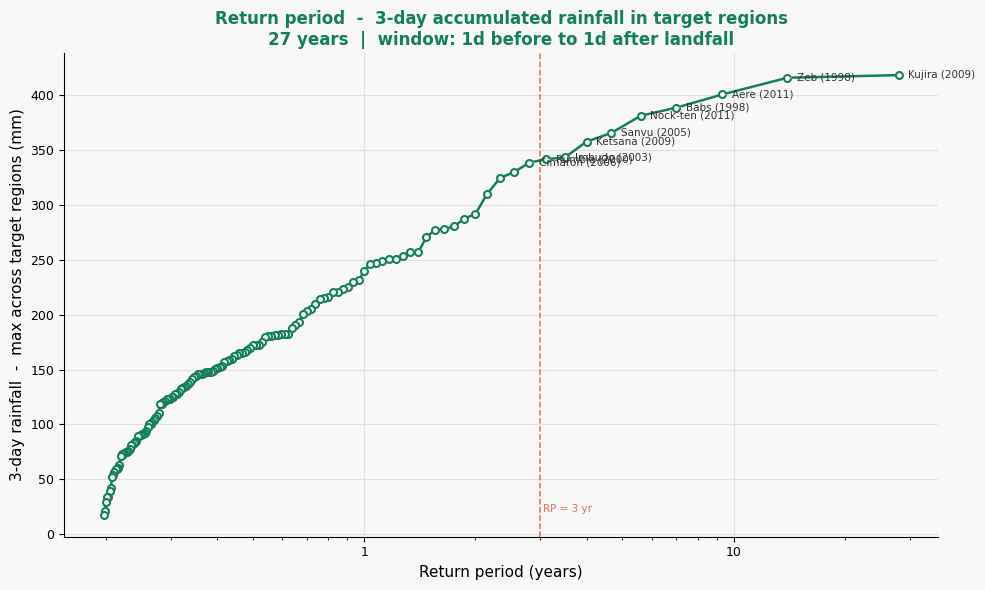

In [13]:
# ── Return period curve ───────────────────────────────────────────────────────
print(f"Record: {N_YEARS} years  |  Storms ranked: {len(exposure)}")

rain_sorted = exposure["max_rain_mm"].sort_values(ascending=False).reset_index(drop=True)
rain_sorted.index += 1
rp_vals = (N_YEARS + 1) / rain_sorted.index.values

top_labels = list(zip(
    rain_sorted.values[:10],
    (exposure.sort_values("max_rain_mm", ascending=False)["name"].values[:10] + " (" +
     exposure.sort_values("max_rain_mm", ascending=False)["year"].astype(int).astype(str).values[:10] + ")"),
))

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

ax.plot(rp_vals, rain_sorted.values, "o-", color=CHD_GREEN, linewidth=1.8,
        markersize=5, markerfacecolor="white", markeredgewidth=1.5, zorder=3)

for val, label in top_labels:
    idx  = np.argmin(np.abs(rain_sorted.values - val))
    rp_v = rp_vals[idx]
    ax.annotate(
        label, xy=(rp_v, val),
        xytext=(7, 0), textcoords="offset points",
        fontsize=7.5, color="#333", va="center",
        arrowprops=dict(arrowstyle="-", color="#ccc", lw=0.5),
    )

ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.axvline(3, color="#e76f51", linewidth=1.1, linestyle="--", zorder=2)
ax.text(3.05, rain_sorted.values.min() * 1.02, "RP = 3 yr",
        fontsize=7.5, color="#e76f51", va="bottom")

ax.set_xlabel("Return period (years)", fontsize=11)
ax.set_ylabel("3-day rainfall  -  max across target regions (mm)", fontsize=11)
ax.set_title(
    "Return period  -  3-day accumulated rainfall in target regions\n"
    f"{N_YEARS} years  |  window: {DAYS_BEFORE}d before to {DAYS_AFTER}d after landfall",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()

In [14]:
# ── Rainfall threshold sweep ──────────────────────────────────────────────────
TARGET_RP = 5.0   # desired return period (years)

thresholds = [75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 350, 400, 500]

exposure_yr = exposure.copy()
exposure_yr["year_int"] = exposure_yr["year"].astype(int)

rows = []
for thr in thresholds:
    above     = exposure_yr[exposure_yr["max_rain_mm"] >= thr]
    n_seasons = above["year_int"].nunique()
    rp        = N_YEARS / n_seasons if n_seasons > 0 else float("inf")
    rows.append({"threshold_mm": thr, "n_seasons": n_seasons,
                 "rp_yr": round(rp, 1), "storms": len(above)})

sweep_df = pd.DataFrame(rows)

# Find the threshold closest to TARGET_RP
finite = sweep_df[sweep_df["rp_yr"] < float("inf")]
best = finite.iloc[(finite["rp_yr"] - TARGET_RP).abs().argmin()]
print(f"Closest threshold to RP {TARGET_RP:.0f} yr: {best['threshold_mm']:.0f} mm "
      f"→ {best['n_seasons']:.0f} seasons, RP {best['rp_yr']:.1f} yr")
print()
print("3-day rainfall threshold sweep:")
print(sweep_df.to_string(index=False))

Closest threshold to RP 5 yr: 300 mm → 7 seasons, RP 3.9 yr

3-day rainfall threshold sweep:
 threshold_mm  n_seasons  rp_yr  storms
           75         26    1.0     123
          100         26    1.0     107
          125         26    1.0      93
          150         26    1.0      71
          175         25    1.1      52
          200         22    1.2      41
          225         18    1.5      31
          250         14    1.9      24
          275         10    2.7      18
          300          7    3.9      13
          350          4    6.8       7
          400          3    9.0       3
          500          0    inf       0


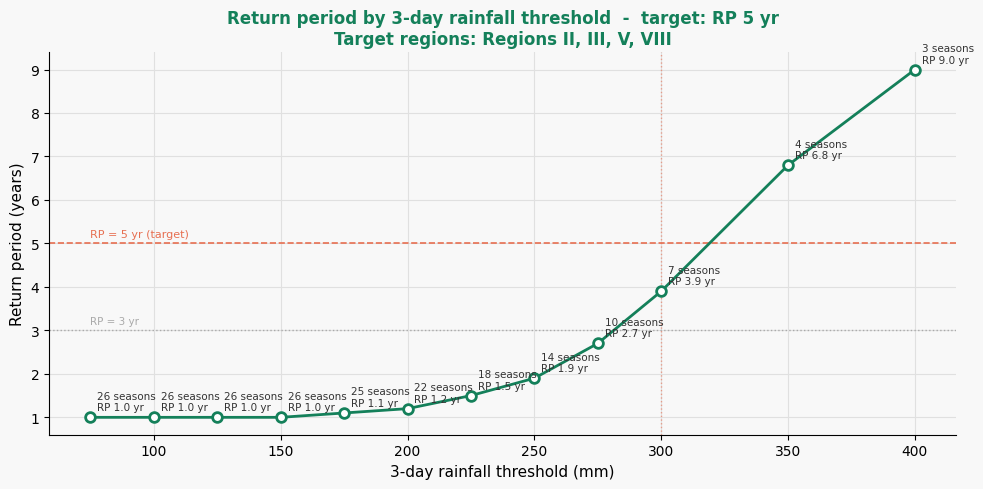

In [15]:
# ── Plot: RP vs rainfall threshold ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

finite = sweep_df[sweep_df["rp_yr"] < 100]
ax.plot(
    finite["threshold_mm"], finite["rp_yr"],
    "o-", color=CHD_GREEN, linewidth=2,
    markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=3,
)
for _, row in finite.iterrows():
    ax.annotate(
        f"{row['n_seasons']:.0f} seasons\nRP {row['rp_yr']:.1f} yr",
        xy=(row["threshold_mm"], row["rp_yr"]),
        xytext=(5, 5), textcoords="offset points",
        fontsize=7.5, color="#333",
    )

# Reference lines
ax.axhline(3.0, color="#aaa", linewidth=1.0, linestyle=":", zorder=2)
ax.text(finite["threshold_mm"].min(), 3.1, "RP = 3 yr",
        fontsize=7.5, color="#aaa", va="bottom")
ax.axhline(TARGET_RP, color="#e76f51", linewidth=1.2, linestyle="--", zorder=2)
ax.text(finite["threshold_mm"].min(), TARGET_RP + 0.1,
        f"RP = {TARGET_RP:.0f} yr (target)",
        fontsize=8, color="#e76f51", va="bottom")

# Highlight the best threshold
ax.axvline(best["threshold_mm"], color="#e76f51", linewidth=1.0,
           linestyle=":", alpha=0.6, zorder=2)

ax.set_xlabel("3-day rainfall threshold (mm)", fontsize=11)
ax.set_ylabel("Return period (years)", fontsize=11)
ax.set_title(
    f"Return period by 3-day rainfall threshold  -  target: RP {TARGET_RP:.0f} yr\n"
    "Target regions: Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

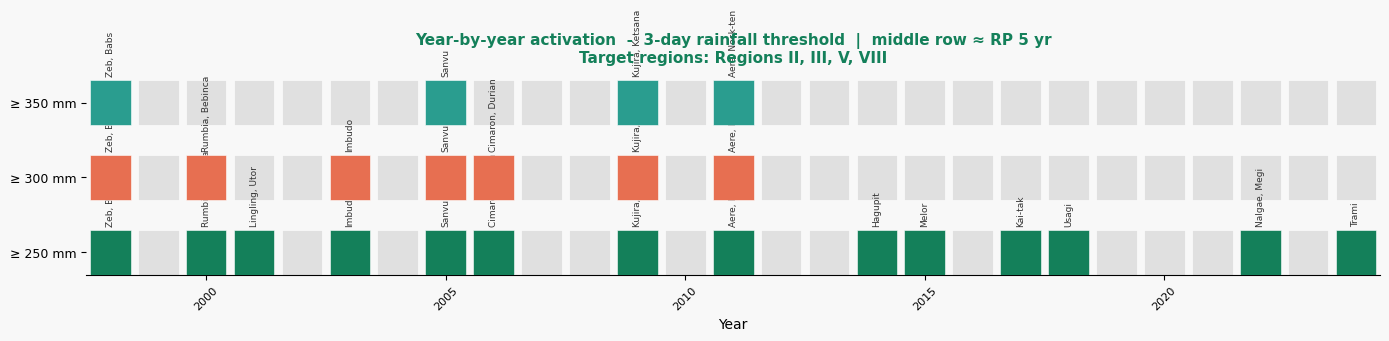

≥ 250 mm: 14 seasons  RP ≈ 1.9 yr  [1998, 2000, 2001, 2003, 2005, 2006, 2009, 2011, 2014, 2015, 2017, 2018, 2022, 2024]
≥ 300 mm:  7 seasons  RP ≈ 3.9 yr  [1998, 2000, 2003, 2005, 2006, 2009, 2011] ← target RP
≥ 350 mm:  4 seasons  RP ≈ 6.8 yr  [1998, 2005, 2009, 2011]


In [16]:
# ── Year-by-year activation timeline ─────────────────────────────────────────
# Three thresholds: one below target RP, the best-fit threshold, one above
THRESHOLD_LOW  = int(best["threshold_mm"]) - 50
THRESHOLD_MID  = int(best["threshold_mm"])        # closest to RP = TARGET_RP
THRESHOLD_HIGH = int(best["threshold_mm"]) + 50

THRESHOLDS_TIMELINE = [THRESHOLD_LOW, THRESHOLD_MID, THRESHOLD_HIGH]
all_years = list(range(START_YEAR, END_YEAR + 1))

def activated_years(thr):
    return set(exposure_yr[exposure_yr["max_rain_mm"] >= thr]["year_int"].dropna().astype(int))

act_sets   = [(thr, activated_years(thr)) for thr in THRESHOLDS_TIMELINE]
colors_t   = [CHD_GREEN, "#e76f51", "#2a9d8f"]

fig, ax = plt.subplots(figsize=(14, 3.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

for i, (thr, act_set) in enumerate(act_sets):
    for yr in all_years:
        if yr in act_set:
            names = exposure_yr[
                (exposure_yr["year_int"] == yr) &
                (exposure_yr["max_rain_mm"] >= thr)
            ]["name"].tolist()
            ax.bar(yr, 0.6, bottom=i - 0.3, color=colors_t[i],
                   width=0.85, zorder=3, edgecolor="white", linewidth=0.4)
            ax.text(yr, i + 0.35, ", ".join(names[:2]),
                    ha="center", va="bottom", fontsize=6.5, color="#333", rotation=90)
        else:
            ax.bar(yr, 0.6, bottom=i - 0.3, color="#e0e0e0",
                   width=0.85, zorder=2, edgecolor="white", linewidth=0.4)

ax.set_yticks(range(len(act_sets)))
ax.set_yticklabels([f"≥ {thr} mm" for thr, _ in act_sets], fontsize=9)
ax.set_xlim(START_YEAR - 0.5, END_YEAR + 0.5)
ax.set_xlabel("Year", fontsize=10)
ax.set_title(
    f"Year-by-year activation  -  3-day rainfall threshold  |  middle row ≈ RP {TARGET_RP:.0f} yr\n"
    "Target regions: Regions II, III, V, VIII",
    fontsize=11, fontweight="bold", color=CHD_GREEN,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="x", labelsize=8, rotation=45)
plt.tight_layout()
plt.show()

for thr, act_set in act_sets:
    rp = N_YEARS / len(act_set) if act_set else float("inf")
    marker = " ← target RP" if thr == THRESHOLD_MID else ""
    print(f"≥ {thr:>3} mm: {len(act_set):>2} seasons  RP ≈ {rp:.1f} yr  {sorted(act_set)}{marker}")

In [17]:
# ── Summary ───────────────────────────────────────────────────────────────────
print("=" * 70)
print("OBSERVATIONAL RAINFALL TRIGGER  -  SUMMARY")
print(f"Record        : {START_YEAR}-{END_YEAR} ({N_YEARS} years)")
print(f"IMERG window  : {DAYS_BEFORE}d before landfall → {DAYS_AFTER}d after landfall ({DAYS_BEFORE+1+DAYS_AFTER} days total)")
print(f"Metric        : 3-day accumulated mean rainfall (mm)  -  max across target regions")
print(f"Storms assessed: {len(exposure)} with landfall in target regions")
print("=" * 70)
print()
print("Rainfall threshold sweep:")
print(sweep_df.to_string(index=False))
print()
print("Top 15 storms (3-day rainfall):")
display(
    exposure[["name", "year", "landfall_date", "max_wind_kmh", "max_rain_mm"]]
    .head(15)
    .rename(columns={"max_rain_mm": "max_3day_mm", "max_wind_kmh": "wind_kmh"})
    .assign(year=lambda d: d["year"].astype(int))
    .reset_index(drop=True)
)

OBSERVATIONAL RAINFALL TRIGGER  -  SUMMARY
Record        : 1998-2024 (27 years)
IMERG window  : 1d before landfall → 1d after landfall (3 days total)
Metric        : 3-day accumulated mean rainfall (mm)  -  max across target regions
Storms assessed: 142 with landfall in target regions

Rainfall threshold sweep:
 threshold_mm  n_seasons  rp_yr  storms
           75         26    1.0     123
          100         26    1.0     107
          125         26    1.0      93
          150         26    1.0      71
          175         25    1.1      52
          200         22    1.2      41
          225         18    1.5      31
          250         14    1.9      24
          275         10    2.7      18
          300          7    3.9      13
          350          4    6.8       7
          400          3    9.0       3
          500          0    inf       0

Top 15 storms (3-day rainfall):


,name,year,landfall_date,wind_kmh,max_3day_mm
0,Kujira,2009,2009-05-01,NaN,418.037654
1,Zeb,1998,1998-10-14,194.5,415.659430
2,Aere,2011,2011-05-07,64.8,400.458058
3,Babs,1998,1998-10-21,157.4,388.408500
4,Nock-ten,2011,2011-07-25,NaN,380.948882
5,Sanvu,2005,2005-08-11,74.1,365.377461
6,Ketsana,2009,2009-09-26,69.4,357.496551
7,Imbudo,2003,2003-07-22,143.5,343.308570
8,Rumbia,2000,2000-11-29,NaN,341.480642
9,Cimaron,2006,2006-10-29,175.9,338.373040


---
## CHIRPS-GEFS Forecast Rainfall by Lead Time

For each storm in the IMERG dataset, match CHIRPS-GEFS forecasts issued 0–5 days before landfall
to the same 3-day window and compute forecast 3-day accumulated rainfall per region.

**Lead 0** = forecast issued on the day of landfall (nowcast).
**Lead 5** = forecast issued 5 days before landfall.

CHIRPS-GEFS provides daily forecast rainfall at 0.05° resolution from 2001 onwards.
The parquet used here (`pa-aa-phl-storms/processed/chirps-gefs/chirps_gefs_adm1.parquet`)
was computed from admin1 zonal means for all 17 Philippine regions.

In [18]:
# ── Load CHIRPS-GEFS parquet (admin1 zonal means) ─────────────────────────────
CONTAINER = "projects"
STAGE     = "dev"
GEFS_BLOB = "pa-aa-phl-storms/processed/chirps-gefs/chirps_gefs_adm1.parquet"

gefs_df = stratus.load_parquet_from_blob(GEFS_BLOB, stage=STAGE, container_name=CONTAINER)
gefs_target = gefs_df[gefs_df["pcode"].isin(TARGET_REGIONS)].copy()
gefs_target["issue_date"] = pd.to_datetime(gefs_target["issue_date"])
gefs_target["valid_date"]  = pd.to_datetime(gefs_target["valid_date"])

print(f"CHIRPS-GEFS rows (4 target regions): {len(gefs_target):,}")
print(f"Lead days in file: {sorted(gefs_target['lead_days'].unique())}")
print(f"Issue date range : {gefs_target['issue_date'].min().date()} to {gefs_target['issue_date'].max().date()}")

CHIRPS-GEFS rows (4 target regions): 6,992
Lead days in file: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Issue date range : 2001-06-29 to 2024-11-15


In [19]:
# ── Match CHIRPS-GEFS to each storm's 3-day landfall window ───────────────────
# lead_from_landfall = landfall_date - issue_date
# Only keep issue dates where all 3 window days are forecast:
#   max CHIRPS-GEFS lead is 6 days, so we need issue_date + 6 >= win_end
#   => lead_from_landfall <= 6 - DAYS_AFTER  (= 5 for DAYS_AFTER = 1)
MAX_LEAD = 6 - DAYS_AFTER

gefs_match_rows = []
for _, row in landfall_df.iterrows():
    lf_date   = pd.Timestamp(row["landfall_date"])
    win_start = lf_date - pd.Timedelta(days=DAYS_BEFORE)
    win_end   = lf_date + pd.Timedelta(days=DAYS_AFTER)

    matched = gefs_target[
        (gefs_target["valid_date"] >= win_start) &
        (gefs_target["valid_date"] <= win_end)
    ].copy()
    if matched.empty:
        continue

    matched["storm_id"]          = row["storm_id"]
    matched["landfall_date"]     = lf_date
    matched["lead_from_landfall"] = (lf_date - matched["issue_date"]).dt.days
    gefs_match_rows.append(matched)

gefs_matched = pd.concat(gefs_match_rows, ignore_index=True)

# Sum the 3-day window per (storm, region, lead_from_landfall)
gefs_3day = (
    gefs_matched
    .groupby(["storm_id", "pcode", "lead_from_landfall"])["mean_mm"]
    .sum()
    .reset_index()
    .rename(columns={"mean_mm": "forecast_3day_mm"})
)
gefs_3day["region"] = gefs_3day["pcode"].map(pcode_to_name)
gefs_3day = gefs_3day[gefs_3day["lead_from_landfall"].between(0, MAX_LEAD)]

# Attach storm metadata
gefs_3day = gefs_3day.merge(
    exposure[["storm_id", "name", "year"]], on="storm_id", how="left"
)
gefs_3day["label"] = (
    gefs_3day["name"] + " (" +
    gefs_3day["year"].fillna(0).astype(int).astype(str) + ")"
)

n_storms = gefs_3day["storm_id"].nunique()
print(f"Storms with CHIRPS-GEFS coverage: {n_storms} / {len(landfall_df)} total")
print(f"  (storms pre-2001 have no GEFS — Zeb 1998, Babs 1998, Rumbia 2000, Bebinca 2000, Xangsane 2000)")
print(f"Lead-from-landfall: 0 (day of landfall) to {MAX_LEAD} (issued {MAX_LEAD} days before)")

Storms with CHIRPS-GEFS coverage: 117 / 142 total
  (storms pre-2001 have no GEFS — Zeb 1998, Babs 1998, Rumbia 2000, Bebinca 2000, Xangsane 2000)
Lead-from-landfall: 0 (day of landfall) to 5 (issued 5 days before)


In [20]:
# ── Align IMERG to CHIRPS-GEFS time span (2001–2024) ─────────────────────────
# GEFS starts 2001; storms from 1998-2000 have IMERG but no GEFS coverage.
# rain_3day_gefs is used for all GEFS vs IMERG comparisons below.
common_storm_ids = set(gefs_3day["storm_id"].unique())
rain_3day_gefs   = rain_3day[rain_3day["storm_id"].isin(common_storm_ids)].copy()

excluded_labels = [
    f"{row['name']} ({int(row['year'])})"
    for _, row in exposure.iterrows()
    if row["storm_id"] not in common_storm_ids
]
print(f"IMERG storms total : {rain_3day['storm_id'].nunique()}")
print(f"With GEFS coverage : {rain_3day_gefs['storm_id'].nunique()}")
print(f"Excluded (pre-2001): {excluded_labels}")

IMERG storms total : 142
With GEFS coverage : 117
Excluded (pre-2001): ['Zeb (1998)', 'Babs (1998)', 'Rumbia (2000)', 'Bebinca (2000)', 'Xangsane (2000)', 'Vamco (2020)', 'Faith (1998)', 'Eve (1999)', 'Sam (1999)', 'Etau (2020)', 'York (1999)', 'Molave (2020)', 'Nuri (2020)', 'Vongfong (2020)', 'Kate (1999)', 'Vicki (1998)', 'Saudel (2020)', 'Goni (2020)', 'Longwang (2000)', 'Dan (1999)', 'Linfa (2020)', 'Maggie (1999)', 'Wendy (1999)', 'Penny (1998)', 'Bopha (2000)']


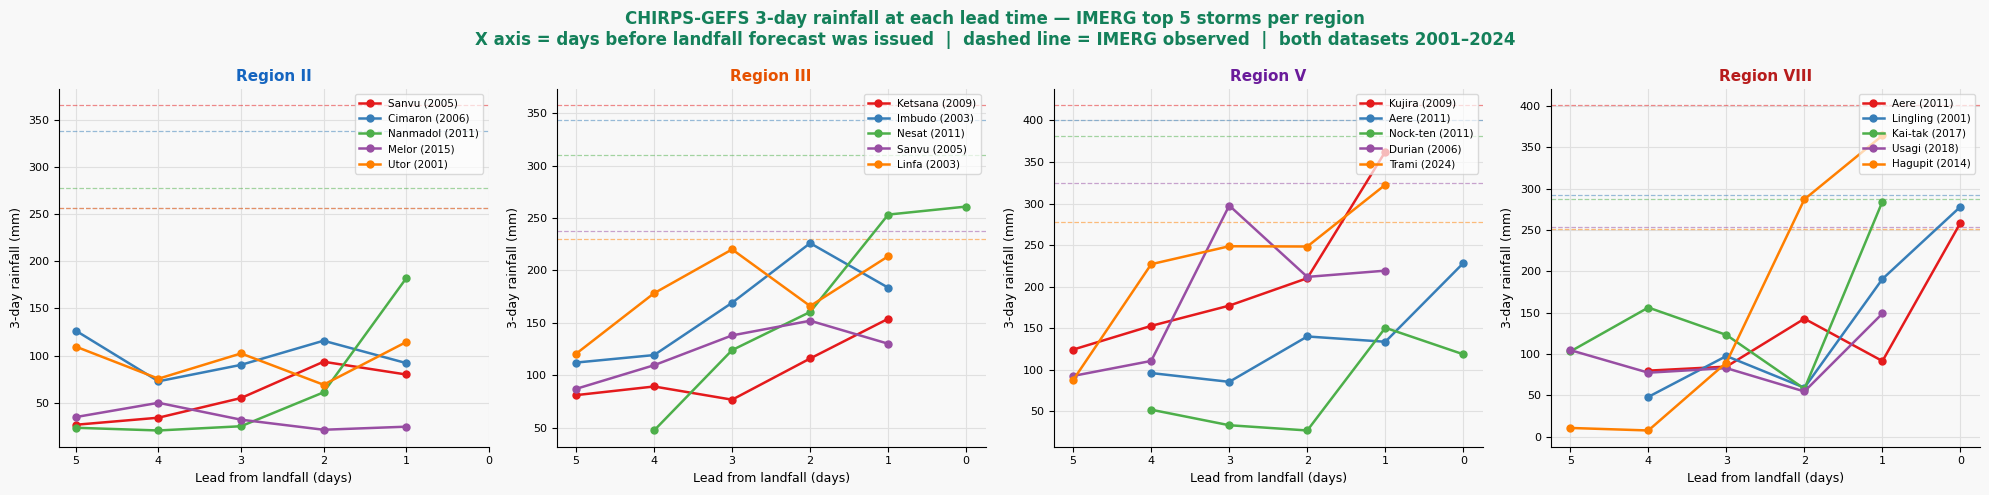

In [21]:
# ── Trace IMERG top 5 storms through CHIRPS-GEFS lead times ───────────────────
# Rankings and reference lines use rain_3day_gefs (2001-2024 only).
TOP_N = 5

FULL_NAMES_4   = [
    "Region II (Cagayan Valley)", "Region III (Central Luzon)",
    "Region V (Bicol Region)",    "Region VIII (Eastern Visayas)",
]
SHORT_NAMES_4  = ["Region II", "Region III", "Region V", "Region VIII"]
REGION_COLORS_4 = ["#1565C0", "#E65100", "#6A1B9A", "#B71C1C"]

# Top 5 per region ranked within the common 2001-2024 window
imerg_top5 = {}
for full in FULL_NAMES_4:
    imerg_top5[full] = (
        rain_3day_gefs[rain_3day_gefs["region"] == full]
        .nlargest(TOP_N, "rain_3day_mm")["storm_id"]
        .tolist()
    )

storm_palette  = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00"]
LEADS          = list(range(0, MAX_LEAD + 1))

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)
fig.patch.set_facecolor("#f8f8f8")
fig.suptitle(
    f"CHIRPS-GEFS 3-day rainfall at each lead time — IMERG top {TOP_N} storms per region\n"
    "X axis = days before landfall forecast was issued  |  dashed line = IMERG observed  "
    "|  both datasets 2001–2024",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)

for ax, full, short, reg_color in zip(axes, FULL_NAMES_4, SHORT_NAMES_4, REGION_COLORS_4):
    ax.set_facecolor("#f8f8f8")

    for i, sid in enumerate(imerg_top5[full]):
        col  = storm_palette[i]
        meta = exposure[exposure["storm_id"] == sid]
        if meta.empty:
            continue
        slabel = meta["name"].iloc[0] + " (" + str(int(meta["year"].iloc[0])) + ")"

        gefs_sub = (
            gefs_3day[
                (gefs_3day["storm_id"] == sid) &
                (gefs_3day["region"] == full)
            ].sort_values("lead_from_landfall")
        )
        if not gefs_sub.empty:
            ax.plot(gefs_sub["lead_from_landfall"], gefs_sub["forecast_3day_mm"],
                    "o-", color=col, linewidth=1.8, markersize=5, label=slabel, zorder=3)

        imerg_val = rain_3day_gefs[
            (rain_3day_gefs["storm_id"] == sid) & (rain_3day_gefs["region"] == full)
        ]["rain_3day_mm"].sum()
        if imerg_val > 0:
            ax.axhline(imerg_val, color=col, linewidth=0.9, linestyle="--", alpha=0.5, zorder=2)

    ax.set_xlabel("Lead from landfall (days)", fontsize=9)
    ax.set_ylabel("3-day rainfall (mm)", fontsize=9)
    ax.set_title(short, fontsize=11, fontweight="bold", color=reg_color)
    ax.set_xticks(LEADS)
    ax.invert_xaxis()
    ax.legend(fontsize=7.5, framealpha=0.7, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.grid(True, color="#e0e0e0")
    ax.yaxis.grid(True, color="#e0e0e0")
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

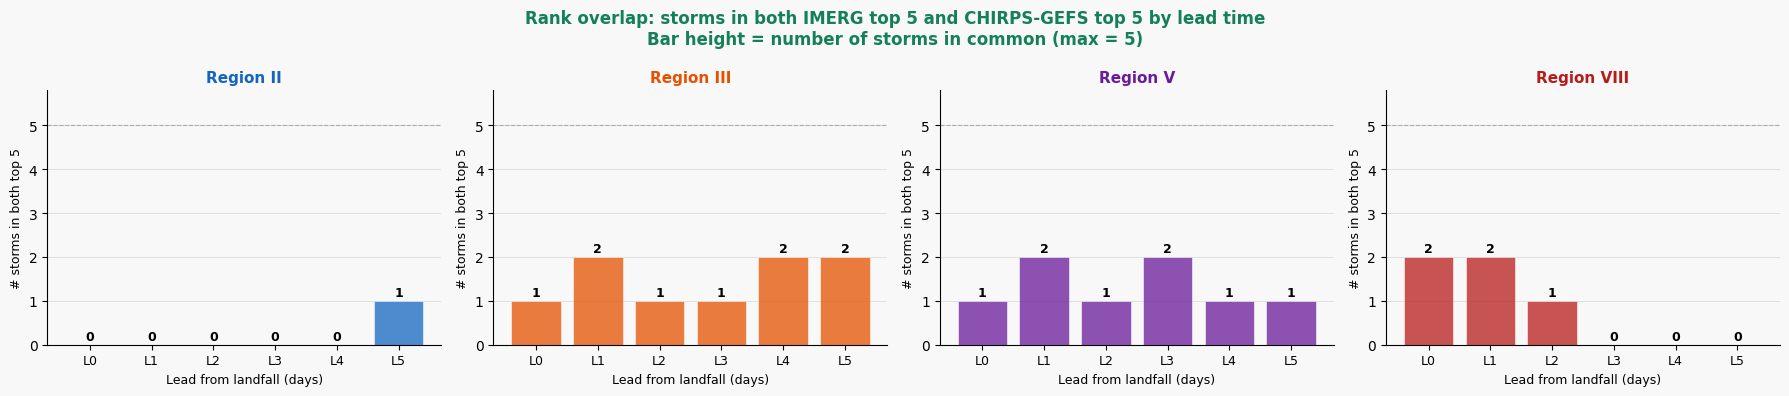


Lead = 3 days before landfall:

  Region II
    IMERG top 5 : ['Sanvu (2005)', 'Cimaron (2006)', 'Nanmadol (2011)', 'Melor (2015)', 'Utor (2001)']
    GEFS top 5  : ['Trami (2024)', 'Megi (2010)', 'Koppu (2015)', 'Nanmadol (2004)', 'Yutu (2018)']

  Region III
    IMERG top 5 : ['Ketsana (2009)', 'Imbudo (2003)', 'Nesat (2011)', 'Sanvu (2005)', 'Linfa (2003)']
    GEFS top 5  : ['Linfa (2003)', 'Koppu (2015)', 'Durian (2006)', 'Nanmadol (2004)', 'Kajiki (2019)']

  Region V
    IMERG top 5 : ['Kujira (2009)', 'Aere (2011)', 'Nock-ten (2011)', 'Durian (2006)', 'Trami (2024)']
    GEFS top 5  : ['Durian (2006)', 'Kammuri (2019)', 'Kai-tak (2017)', 'Trami (2024)', 'Melor (2015)']

  Region VIII
    IMERG top 5 : ['Aere (2011)', 'Lingling (2001)', 'Kai-tak (2017)', 'Usagi (2018)', 'Hagupit (2014)']
    GEFS top 5  : ['Haiyan (2013)', 'Tokage (2016)', 'Utor (2006)', 'Kajiki (2001)', 'Rai (2021)']


In [22]:
# ── Rank overlap: how many IMERG top 5 appear in CHIRPS-GEFS top 5 by lead ────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.patch.set_facecolor("#f8f8f8")
fig.suptitle(
    f"Rank overlap: storms in both IMERG top {TOP_N} and CHIRPS-GEFS top {TOP_N} by lead time\n"
    "Bar height = number of storms in common (max = 5)",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)

for ax, full, short, reg_color in zip(axes, FULL_NAMES_4, SHORT_NAMES_4, REGION_COLORS_4):
    ax.set_facecolor("#f8f8f8")

    imerg_set = set(imerg_top5[full])
    overlaps  = []
    for lead in LEADS:
        gefs_top = set(
            gefs_3day[
                (gefs_3day["region"] == full) &
                (gefs_3day["lead_from_landfall"] == lead)
            ].nlargest(TOP_N, "forecast_3day_mm")["storm_id"].tolist()
        )
        overlaps.append(len(imerg_set & gefs_top))

    bars = ax.bar(
        LEADS, overlaps, color=reg_color, alpha=0.75,
        edgecolor="white", linewidth=0.5,
    )
    for bar, val in zip(bars, overlaps):
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            str(val), ha="center", va="bottom", fontsize=9, fontweight="bold",
        )

    ax.axhline(TOP_N, color="#aaa", linewidth=0.8, linestyle="--", zorder=2)
    ax.set_xticks(LEADS)
    ax.set_xticklabels([f"L{l}" for l in LEADS], fontsize=9)
    ax.set_xlabel("Lead from landfall (days)", fontsize=9)
    ax.set_ylabel(f"# storms in both top {TOP_N}", fontsize=9)
    ax.set_ylim(0, TOP_N + 0.8)
    ax.set_title(short, fontsize=11, fontweight="bold", color=reg_color)
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Print the IMERG top 5 vs GEFS top 5 for lead=3 (most operationally relevant)
print("\nLead = 3 days before landfall:")
for full, short in zip(FULL_NAMES_4, SHORT_NAMES_4):
    imerg_names = [
        exposure[exposure["storm_id"] == sid]["name"].values[0]
        + " (" + str(int(exposure[exposure["storm_id"] == sid]["year"].values[0])) + ")"
        for sid in imerg_top5[full]
        if len(exposure[exposure["storm_id"] == sid]) > 0
    ]
    gefs_top3_ids = (
        gefs_3day[
            (gefs_3day["region"] == full) &
            (gefs_3day["lead_from_landfall"] == 3)
        ].nlargest(TOP_N, "forecast_3day_mm")["storm_id"].tolist()
    )
    gefs_names = [
        exposure[exposure["storm_id"] == sid]["name"].values[0]
        + " (" + str(int(exposure[exposure["storm_id"] == sid]["year"].values[0])) + ")"
        for sid in gefs_top3_ids
        if len(exposure[exposure["storm_id"] == sid]) > 0
    ]
    print(f"\n  {short}")
    print(f"    IMERG top 5 : {imerg_names}")
    print(f"    GEFS top 5  : {gefs_names}")

---
## CHIRPS-GEFS Forecast Skill vs IMERG

**Context — IMERG latency:** IMERG Late Run has ~18-hour latency per day.
To accumulate the full 3-day window (day −1, day 0, day +1 around landfall),
you would need to wait roughly **2 days after landfall** for IMERG to be complete —
making it unusable for anticipatory action. CHIRPS-GEFS can fill this gap.

The question is: at what lead time does CHIRPS-GEFS most closely approximate
what IMERG would measure? Pearson R and RMSE are computed between the GEFS forecast
3-day accumulated rainfall and the IMERG observed 3-day rainfall, for all storms
with both datasets available (2001–2024, n ≈ 100+ storms per region).

In [23]:
from scipy import stats

# Skill metrics: CHIRPS-GEFS vs IMERG, 2001-2024 only (rain_3day_gefs)
skill_rows = []

for lead in LEADS:
    gefs_lead = gefs_3day[gefs_3day["lead_from_landfall"] == lead][
        ["storm_id", "pcode", "forecast_3day_mm"]
    ]
    merged = rain_3day_gefs.merge(gefs_lead, on=["storm_id", "pcode"], how="inner")

    for full, short in zip(FULL_NAMES_4, SHORT_NAMES_4):
        sub = merged[merged["region"] == full].dropna(
            subset=["rain_3day_mm", "forecast_3day_mm"]
        )
        if len(sub) < 5:
            continue
        r, _  = stats.pearsonr(sub["rain_3day_mm"], sub["forecast_3day_mm"])
        rmse   = np.sqrt(((sub["forecast_3day_mm"] - sub["rain_3day_mm"]) ** 2).mean())
        bias   = (sub["forecast_3day_mm"] - sub["rain_3day_mm"]).mean()
        skill_rows.append(
            dict(lead=lead, region=short, n=len(sub),
                 pearson_r=round(r, 3), r2=round(r**2, 3),
                 rmse_mm=round(rmse, 1), bias_mm=round(bias, 1))
        )

skill_df = pd.DataFrame(skill_rows)
print("CHIRPS-GEFS vs IMERG skill  |  2001–2024 storms only\n")
print(skill_df.to_string(index=False))

CHIRPS-GEFS vs IMERG skill  |  2001–2024 storms only

 lead      region   n  pearson_r    r2  rmse_mm  bias_mm
    0   Region II  28      0.628 0.394     69.8    -23.9
    0  Region III  28      0.880 0.774     39.8    -18.7
    0    Region V  28      0.754 0.568     77.8    -35.8
    0 Region VIII  28      0.886 0.785     49.5    -17.9
    1   Region II 117      0.571 0.326     70.7    -12.6
    1  Region III 117      0.703 0.495     51.1     -9.6
    1    Region V 117      0.736 0.542     59.3     -8.7
    1 Region VIII 117      0.742 0.551     53.7     -3.3
    2   Region II 117      0.554 0.307     73.9    -26.1
    2  Region III 117      0.640 0.409     59.3    -22.7
    2    Region V 117      0.617 0.381     73.5    -27.1
    2 Region VIII 117      0.640 0.409     63.4    -17.3
    3   Region II 117      0.461 0.213     82.1    -33.3
    3  Region III 117      0.500 0.250     68.1    -28.1
    3    Region V 117      0.552 0.305     78.0    -26.7
    3 Region VIII 117      0.590 0

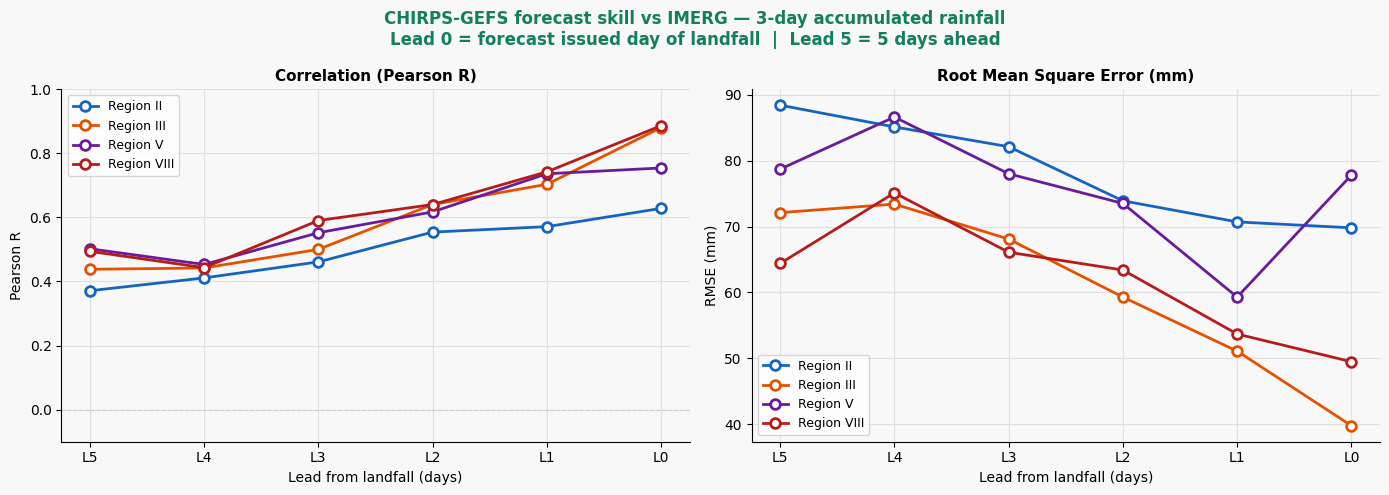


Best lead time per region (highest Pearson R):
  Region II: lead 0 (R = 0.628, RMSE = 69.8 mm, bias = -23.9 mm, n = 28)
  Region III: lead 0 (R = 0.880, RMSE = 39.8 mm, bias = -18.7 mm, n = 28)
  Region V: lead 0 (R = 0.754, RMSE = 77.8 mm, bias = -35.8 mm, n = 28)
  Region VIII: lead 0 (R = 0.886, RMSE = 49.5 mm, bias = -17.9 mm, n = 28)


In [24]:
# ── Skill vs lead time: Pearson R and RMSE per region ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#f8f8f8")
fig.suptitle(
    "CHIRPS-GEFS forecast skill vs IMERG — 3-day accumulated rainfall\n"
    "Lead 0 = forecast issued day of landfall  |  Lead 5 = 5 days ahead",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)

# Left: Pearson R
ax = axes[0]
ax.set_facecolor("#f8f8f8")
for short, color in zip(SHORT_NAMES_4, REGION_COLORS_4):
    sub = skill_df[skill_df["region"] == short].sort_values("lead")
    ax.plot(sub["lead"], sub["pearson_r"], "o-", color=color, label=short,
            linewidth=2, markersize=7, markerfacecolor="white", markeredgewidth=2)
ax.axhline(0, color="#ccc", linewidth=0.8, linestyle="--")
ax.set_xlabel("Lead from landfall (days)", fontsize=10)
ax.set_ylabel("Pearson R", fontsize=10)
ax.set_title("Correlation (Pearson R)", fontsize=11, fontweight="bold")
ax.set_xticks(LEADS)
ax.set_xticklabels([f"L{l}" for l in LEADS])
ax.invert_xaxis()   # L5 on left (furthest out), L0 on right (nowcast)
ax.legend(fontsize=9, framealpha=0.8)
ax.set_ylim(-0.1, 1.0)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, color="#e0e0e0")
ax.yaxis.grid(True, color="#e0e0e0")
ax.set_axisbelow(True)

# Right: RMSE
ax = axes[1]
ax.set_facecolor("#f8f8f8")
for short, color in zip(SHORT_NAMES_4, REGION_COLORS_4):
    sub = skill_df[skill_df["region"] == short].sort_values("lead")
    ax.plot(sub["lead"], sub["rmse_mm"], "o-", color=color, label=short,
            linewidth=2, markersize=7, markerfacecolor="white", markeredgewidth=2)
ax.set_xlabel("Lead from landfall (days)", fontsize=10)
ax.set_ylabel("RMSE (mm)", fontsize=10)
ax.set_title("Root Mean Square Error (mm)", fontsize=11, fontweight="bold")
ax.set_xticks(LEADS)
ax.set_xticklabels([f"L{l}" for l in LEADS])
ax.invert_xaxis()
ax.legend(fontsize=9, framealpha=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, color="#e0e0e0")
ax.yaxis.grid(True, color="#e0e0e0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Best lead per region
print("\nBest lead time per region (highest Pearson R):")
for short in SHORT_NAMES_4:
    sub = skill_df[skill_df["region"] == short]
    best = sub.loc[sub["pearson_r"].idxmax()]
    print(f"  {short}: lead {int(best['lead'])} "
          f"(R = {best['pearson_r']:.3f}, RMSE = {best['rmse_mm']:.1f} mm, "
          f"bias = {best['bias_mm']:+.1f} mm, n = {int(best['n'])})")

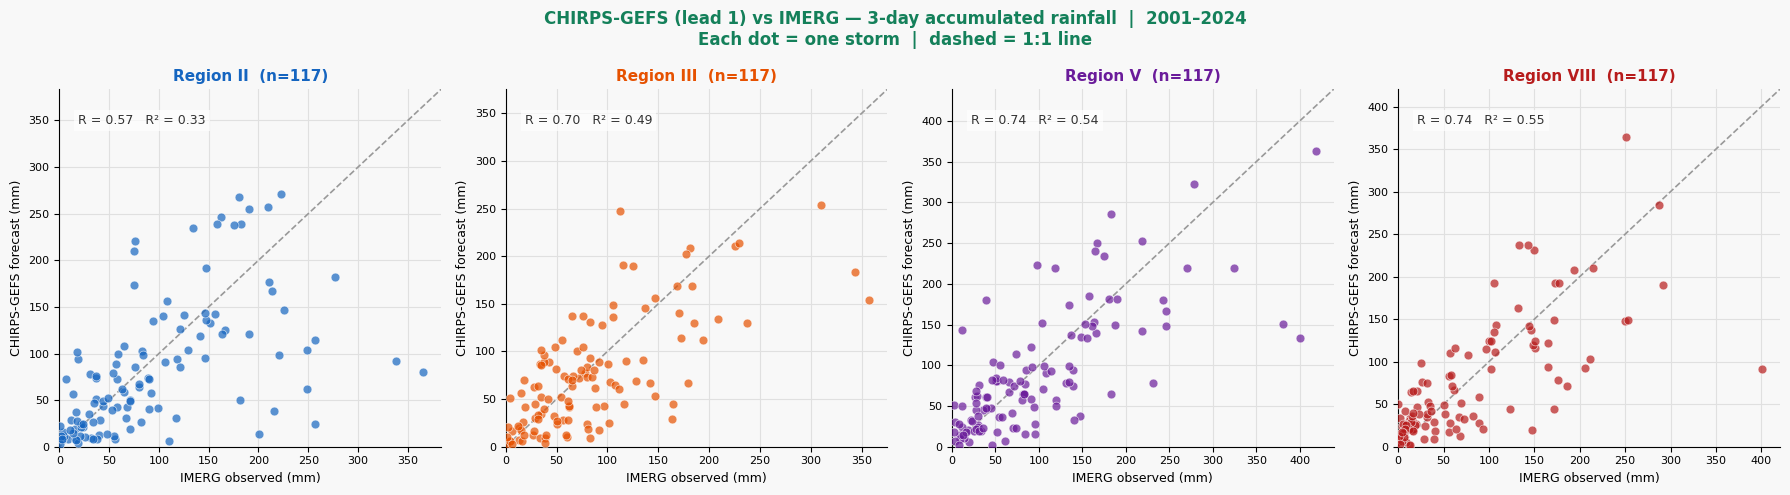

In [25]:
# ── Scatter: GEFS vs IMERG at lead = 3 days (2001–2024 storms only) ───────────
TARGET_LEAD = 1

gefs_lead3 = gefs_3day[gefs_3day["lead_from_landfall"] == TARGET_LEAD][
    ["storm_id", "pcode", "forecast_3day_mm", "label"]
]
scatter_df = rain_3day_gefs.merge(gefs_lead3, on=["storm_id", "pcode"], how="inner")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.patch.set_facecolor("#f8f8f8")
fig.suptitle(
    f"CHIRPS-GEFS (lead {TARGET_LEAD}) vs IMERG — 3-day accumulated rainfall  |  2001–2024\n"
    "Each dot = one storm  |  dashed = 1:1 line",
    fontsize=12, fontweight="bold", color=CHD_GREEN,
)

for ax, full, short, color in zip(axes, FULL_NAMES_4, SHORT_NAMES_4, REGION_COLORS_4):
    ax.set_facecolor("#f8f8f8")
    sub = scatter_df[scatter_df["region"] == full].dropna(
        subset=["rain_3day_mm", "forecast_3day_mm"]
    )
    if sub.empty:
        ax.set_title(short); continue

    ax.scatter(sub["rain_3day_mm"], sub["forecast_3day_mm"],
               color=color, alpha=0.7, s=40, edgecolors="white", linewidths=0.5, zorder=3)

    lim = max(sub["rain_3day_mm"].max(), sub["forecast_3day_mm"].max()) * 1.05
    ax.plot([0, lim], [0, lim], "--", color="#999", linewidth=1.2, zorder=2)

    r_val  = skill_df[(skill_df["region"] == short) & (skill_df["lead"] == TARGET_LEAD)]["pearson_r"].values
    r2_val = skill_df[(skill_df["region"] == short) & (skill_df["lead"] == TARGET_LEAD)]["r2"].values
    if len(r_val):
        ax.text(0.05, 0.93, f"R = {r_val[0]:.2f}   R² = {r2_val[0]:.2f}",
                transform=ax.transAxes, fontsize=9, color="#333",
                va="top", bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=3))

    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("IMERG observed (mm)", fontsize=9)
    ax.set_ylabel("CHIRPS-GEFS forecast (mm)", fontsize=9)
    ax.set_title(f"{short}  (n={len(sub)})", fontsize=11, fontweight="bold", color=color)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.grid(True, color="#e0e0e0")
    ax.yaxis.grid(True, color="#e0e0e0")
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

In [26]:
# ── Save rainfall trigger forecast data (lead = 1 day before landfall) ────────
# Lead 1 has the highest CHIRPS-GEFS skill vs IMERG across all regions.
TARGET_SAVE_LEAD = 1

_save_rain = (
    gefs_3day[gefs_3day["lead_from_landfall"] == TARGET_SAVE_LEAD]
    .groupby(["storm_id", "name", "year"])["forecast_3day_mm"]
    .max()
    .reset_index()
    .rename(columns={"forecast_3day_mm": "max_forecast_3day_mm"})
    .sort_values("year")
    .reset_index(drop=True)
)

_blob = "pa-aa-phl-storms/processed/trigger_activations/obs_rainfall.parquet"
stratus.upload_parquet_to_blob(_save_rain, _blob, stage=STAGE, container_name=CONTAINER)
print(f"Saved {len(_save_rain)} storms → {_blob}")
print(_save_rain.to_string(index=False))

Saved 117 storms → pa-aa-phl-storms/processed/trigger_activations/obs_rainfall.parquet
         storm_id      name   year  max_forecast_3day_mm
 lingling_wp_2001  Lingling 2001.0            190.669918
   kajiki_wp_2001    Kajiki 2001.0            231.044347
     utor_wp_2001      Utor 2001.0            134.013303
   imbudo_wp_2003    Imbudo 2003.0            183.468920
    linfa_wp_2003     Linfa 2003.0            213.462166
  krovanh_wp_2003   Krovanh 2003.0            148.664996
    melor_wp_2003     Melor 2003.0            239.014905
     koni_wp_2003      Koni 2003.0            143.514831
  morakot_wp_2003   Morakot 2003.0             63.499004
 nepartak_wp_2003  Nepartak 2003.0            124.358098
   merbok_wp_2004    Merbok 2004.0            220.418925
    muifa_wp_2004     Muifa 2004.0            114.349336
 mindulle_wp_2004  Mindulle 2004.0            120.554510
 nanmadol_wp_2004  Nanmadol 2004.0            247.862040
  chanthu_wp_2004   Chanthu 2004.0             17.060649
 